        # Lesson 8.6 · CNNs Up Close: Image Classification
        ### Convolutions by hand, pooling, receptive fields, feature maps, data augmentation, and a full CNN classifier

        | | |
        |---|---|
        | ⏱️ **Time** | about 110 minutes |
        | 📚 **Before you start** | Lessons 8.4 – 8.5 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Implement a **2-D convolution** from scratch and see it detect edges
- Compute **output sizes** and **parameter counts** for conv/pool layers
- Train a modern CNN block (**Conv → BatchNorm → ReLU → Pool**) and inspect its **filters and feature maps**
- Use **data augmentation** to fight overfitting on small image sets

> 🌾 **The story so far.** Crop disease detection (next lesson) will be image classification on leaves. First we master the machinery on a cleaner problem: recognising coloured, randomly rotated shapes: circles, squares, triangles and crosses.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
torch.set_num_threads(1)
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · The convolution, by hand

A **filter** (kernel) is a tiny grid of weights. Place it on the image, multiply element-wise with the pixels underneath, **sum** → one output number. Slide it along → a **feature map**.

$$\text{out}[i,j]=\sum_{u,v}\text{img}[i+u,\;j+v]\cdot K[u,v]$$

(Deep-learning "convolution" is technically *cross-correlation*; no kernel flip. Nobody minds.)
A handcrafted **Sobel** kernel detects vertical edges: left column negative, right column positive → big response where dark meets light.

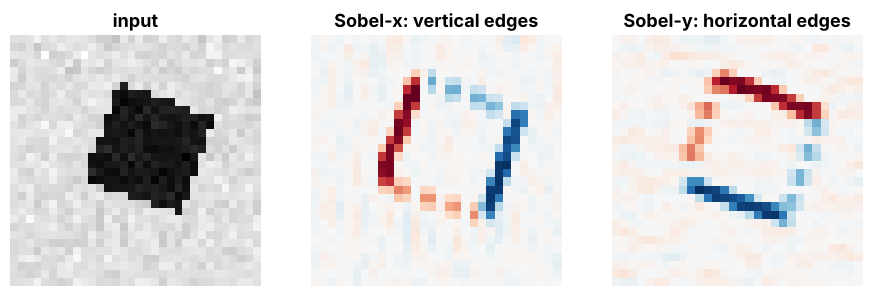

In [2]:
def conv2d_demo(img, k):
    H, W = img.shape; kh, kw = k.shape
    out = np.zeros((H - kh + 1, W - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(img[i:i + kh, j:j + kw] * k)
    return out

sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)
sobel_y = sobel_x.T
Xs, ys, names = ag.make_shapes_dataset(n_per_class=300, size=32, seed=0)
gray = Xs[np.where(ys == 1)[0][0]].mean(axis=2) / 255.0          # one square, as grayscale

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("input")
axes[1].imshow(conv2d_demo(gray, sobel_x), cmap="RdBu"); axes[1].set_title("Sobel-x: vertical edges")
axes[2].imshow(conv2d_demo(gray, sobel_y), cmap="RdBu"); axes[2].set_title("Sobel-y: horizontal edges")
for a in axes: a.axis("off")
plt.show()

The network's job is to **learn** useful kernels instead of us hand-designing them. Layer 1 typically rediscovers edge/colour detectors; deeper layers combine them into corners, curves, textures, parts.

### Shapes and sizes: the formula you will use weekly
For input width $W$, kernel $K$, padding $P$, stride $S$:
$$W_\text{out}=\left\lfloor\frac{W-K+2P}{S}\right\rfloor+1$$

| Layer | Parameters | Notes |
|---|---|---|
| `Conv2d(C_in, C_out, K)` | $C_\text{out}(C_\text{in}K^2+1)$ | independent of image size: **weight sharing** |
| `MaxPool2d(2)` | 0 | halves H and W |
| `Linear(n_in, n_out)` | $n_\text{in}n_\text{out}+n_\text{out}$ | grows with image size! |
| `BatchNorm2d(C)` | $2C$ (+ running stats) | |

**Receptive field:** each output pixel "sees" a region of the input. Stacked 3×3 convolutions grow it by 2 per layer; pooling doubles the growth. Deep = large effective view with few parameters (two 3×3 layers see 5×5 using 18 weights, not 25).

---
### 🧩 Exercise 1: Implement convolution and compare with PyTorch  ⭐⭐

Write `conv2d_valid(img, k)` for a single-channel image (no padding, stride 1): output shape `(H-kh+1, W-kw+1)`. Compute `my_edges = conv2d_valid(gray, sobel_x)`
and verify it equals `F.conv2d` (note: PyTorch wants shapes `(N, C, H, W)` for the image and `(C_out, C_in, kh, kw)` for the kernel).

<details><summary>💡 Hint 1: gentle nudge</summary>

Allocate `out = np.zeros((H - kh + 1, W - kw + 1))`, then two nested loops over output positions.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`out[i, j] = np.sum(img[i:i+kh, j:j+kw] * k)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Reference: `F.conv2d(torch.tensor(gray)[None, None].float(), torch.tensor(sobel_x)[None, None].float())[0, 0].numpy()`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [3]:
def conv2d_valid(img, k):
    H, W = img.shape; kh, kw = k.shape
    out = np.zeros((H - kh + 1, W - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(img[i:i + kh, j:j + kw] * k)
    return out

my_edges = conv2d_valid(gray, sobel_x)
print(my_edges.shape)

(30, 30)


In [4]:
ref = F.conv2d(torch.tensor(gray)[None, None].float(), torch.tensor(sobel_x)[None, None].float())[0, 0].numpy()
ag.check("shape is (30, 30)", my_edges is not None and my_edges.shape == (30, 30))
ag.check("matches torch.nn.functional.conv2d", my_edges is not None and np.allclose(my_edges, ref, atol=1e-4))

✅  shape is (30, 30)
✅  matches torch.nn.functional.conv2d


True

---
### 🧩 Exercise 2: Shape and parameter bookkeeping  ⭐

An RGB 32×32 image passes through: `Conv2d(3,16,3,padding=1)` → `MaxPool2d(2)` → `Conv2d(16,32,3,padding=1)` → `MaxPool2d(2)` → `Conv2d(32,64,3,padding=1)` → `MaxPool2d(2)`.
Write `conv_out(w, k, p=0, s=1)` and use it to compute:
- `sizes`: the list of spatial sizes after each of the 6 layers (starting from 32);
- `n_conv_params`: total parameters of the three conv layers.

<details><summary>💡 Hint 1: gentle nudge</summary>

`conv_out = lambda w, k, p=0, s=1: (w - k + 2*p) // s + 1`; pooling is `conv_out(w, 2, 0, 2)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Sizes: 32 → 32 → 16 → 16 → 8 → 8 → 4 (conv keeps size with padding 1; pool halves).

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Params: `16*(3*9+1) + 32*(16*9+1) + 64*(32*9+1)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [5]:
def conv_out(w, k, p=0, s=1):
    return (w - k + 2 * p) // s + 1

sizes, w = [], 32
for kind in ["conv", "pool", "conv", "pool", "conv", "pool"]:
    w = conv_out(w, 3, 1, 1) if kind == "conv" else conv_out(w, 2, 0, 2)
    sizes.append(w)
n_conv_params = 16 * (3 * 9 + 1) + 32 * (16 * 9 + 1) + 64 * (32 * 9 + 1)
print(sizes, n_conv_params)

[32, 16, 16, 8, 8, 4] 23584


In [6]:
ag.check("sizes after each layer are 32,16,16,8,8,4", sizes == [32, 16, 16, 8, 8, 4])
ag.check("conv parameters = 448 + 4,640 + 18,496 = 23,584", n_conv_params == 23584)

✅  sizes after each layer are 32,16,16,8,8,4
✅  conv parameters = 448 + 4,640 + 18,496 = 23,584


True

---
## 2 · The dataset: shapes in the wild

1,200 RGB images (32×32): four classes with **random colours, backgrounds, positions, sizes, rotations and noise**: so colour and orientation are *not* clues; only shape is.
PyTorch wants **channels-first** tensors `(N, C, H, W)`; we normalise per channel with **training** statistics.

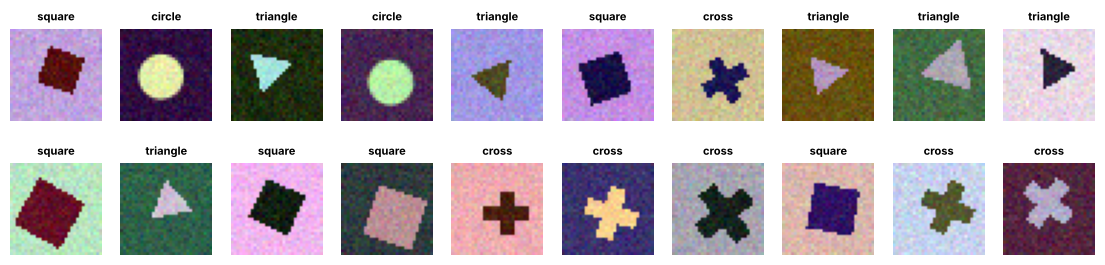

train / val / test: (720, 3, 32, 32) 240 240


In [7]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for ax, i in zip(axes.ravel(), range(20)):
    ax.imshow(Xs[i]); ax.set_title(names[ys[i]], fontsize=8); ax.axis("off")
plt.show()

idx = np.random.default_rng(0).permutation(len(ys)); n = len(ys)
tr_i, va_i, te_i = idx[: int(.6 * n)], idx[int(.6 * n): int(.8 * n)], idx[int(.8 * n):]
to_nchw = lambda a: torch.tensor(a.astype(np.float32) / 255.0).permute(0, 3, 1, 2)
Xall = to_nchw(Xs); mean, std = Xall[tr_i].mean((0, 2, 3), keepdim=True), Xall[tr_i].std((0, 2, 3), keepdim=True)
Xall = (Xall - mean) / std
yall = torch.tensor(ys, dtype=torch.long)
Xtr, ytr, Xva, yva, Xte, yte = Xall[tr_i], yall[tr_i], Xall[va_i], yall[va_i], Xall[te_i], yall[te_i]
print("train / val / test:", tuple(Xtr.shape), len(Xva), len(Xte))

## 3 · A modern CNN

Building block used everywhere: **Conv → BatchNorm → ReLU → (Pool)**.
After the last block we use **global average pooling** (average each feature map down to one number): it removes the huge `Flatten→Linear` layer, cutting parameters and making the model indifferent to input size.

parameters: 60948


epochs run: 27 | validation acc 0.979 | TEST acc 0.983


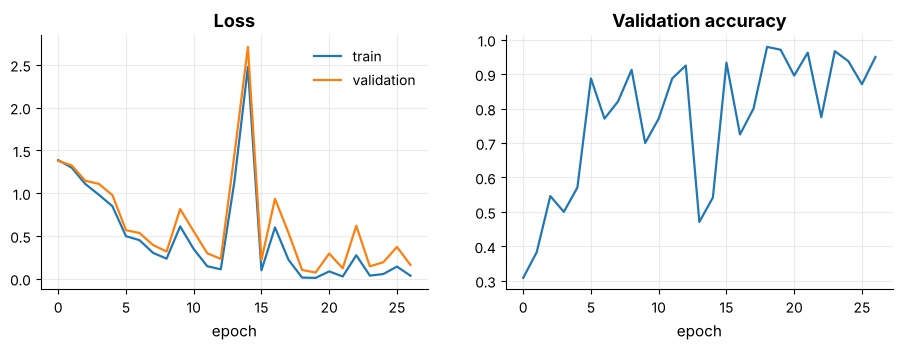

In [8]:
def block(cin, cout, pool=True):
    layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU()]
    return nn.Sequential(*layers, nn.MaxPool2d(2)) if pool else nn.Sequential(*layers)

class ShapeNet(nn.Module):
    def __init__(self, n_classes=4, width=16):
        super().__init__()
        self.features = nn.Sequential(block(3, width), block(width, 2 * width), block(2 * width, 4 * width), block(4 * width, 4 * width, pool=False))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(4 * width, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def train_cnn(model, Xtr, ytr, Xva, yva, epochs=40, lr=3e-3, batch=64, patience=8, aug=None, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3); lossf = nn.CrossEntropyLoss()
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * int(np.ceil(len(Xtr) / batch)))
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch, shuffle=True)
    best, best_state, wait, hist = -1, None, 0, []
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            if aug: xb = aug(xb)
            opt.zero_grad(); lossf(model(xb), yb).backward(); opt.step(); sched.step()
        model.eval()
        with torch.no_grad():
            tl = lossf(model(Xtr), ytr).item(); out = model(Xva); vl = lossf(out, yva).item(); va = (out.argmax(1) == yva).float().mean().item()
        hist.append((tl, vl, va))
        if va > best: best, best_state, wait = va, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model, np.array(hist)

def acc(model, X, y):
    model.eval()
    with torch.no_grad(): return (model(X).argmax(1) == y).float().mean().item()

net = ShapeNet()
print("parameters:", sum(p.numel() for p in net.parameters()))
net, hist = train_cnn(net, Xtr, ytr, Xva, yva)
print(f"epochs run: {len(hist)} | validation acc {acc(net, Xva, yva):.3f} | TEST acc {acc(net, Xte, yte):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(hist[:, 0], label="train"); axes[0].plot(hist[:, 1], label="validation"); axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend()
axes[1].plot(hist[:, 2]); axes[1].set(title="Validation accuracy", xlabel="epoch"); plt.show()

---
### 🧩 Exercise 3: Design your own CNN  ⭐⭐

Define `TinyShapeNet(nn.Module)`: **three** blocks using the `block` helper: 3→8 (with pooling), 8→16 (with pooling), 16→32 (**no** pooling): followed by global average pooling, `Flatten` and `Linear(32, 4)`.
Train it with `train_cnn(TinyShapeNet(), Xtr, ytr, Xva, yva)` (seed 0). Store `tiny` (trained), `tiny_acc` (test accuracy), `tiny_params`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`self.net = nn.Sequential(block(3, 8), block(8, 16), block(16, 32, pool=False), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(32, 4))`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Parameter count: conv weights (no bias) 3·8·9 + 8·16·9 + 16·32·9 = 5,976, BatchNorm 2·(8+16+32) = 112, linear 32·4 + 4 = 132 → 6,220.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`tiny, _ = train_cnn(TinyShapeNet(), Xtr, ytr, Xva, yva)`; `tiny_acc = acc(tiny, Xte, yte)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [9]:
class TinyShapeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(block(3, 8), block(8, 16), block(16, 32, pool=False), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(32, 4))
    def forward(self, x):
        return self.net(x)

tiny, _ = train_cnn(TinyShapeNet(), Xtr, ytr, Xva, yva)
tiny_acc = acc(tiny, Xte, yte)
tiny_params = sum(p.numel() for p in tiny.parameters())
print(tiny_params, "parameters | test accuracy", round(tiny_acc, 3))

6220 parameters | test accuracy 0.983


In [10]:
ag.check("outputs 4 class logits", tiny is not None and tuple(tiny(Xte[:3]).shape) == (3, 4))
ag.check("6,220 parameters", tiny_params == 6220)
ag.check("test accuracy above 85 %", tiny_acc is not None and tiny_acc > 0.85)

✅  outputs 4 class logits
✅  6,220 parameters
✅  test accuracy above 85 %


True

---
## 4 · Opening the black box: filters and feature maps
The first layer's 3×3×3 filters can be drawn as tiny colour images; feature maps show what each filter "lights up" on a real input.

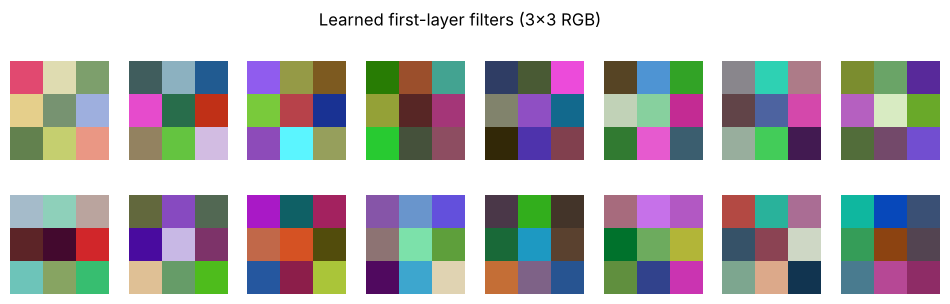

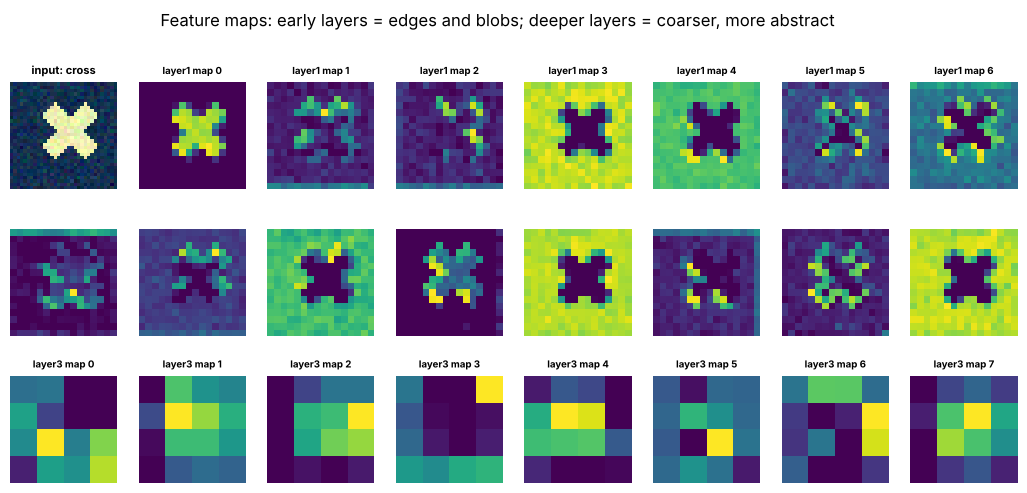

In [11]:
W1 = net.features[0][0].weight.detach()                                   # (16, 3, 3, 3)
Wn = (W1 - W1.min()) / (W1.max() - W1.min())
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, f in zip(axes.ravel(), Wn): ax.imshow(f.permute(1, 2, 0)); ax.axis("off")
plt.suptitle("Learned first-layer filters (3x3 RGB)", y=1.02); plt.show()

sample = Xte[:1]; label = names[yte[0].item()]
with torch.no_grad():
    f1 = net.features[0](sample)[0]; f3 = net.features[:3](sample)[0]
fig, axes = plt.subplots(3, 8, figsize=(13, 5.4))
axes[0, 0].imshow(sample[0].permute(1, 2, 0) * std[0].permute(1, 2, 0) + mean[0].permute(1, 2, 0)); axes[0, 0].set_title(f"input: {label}", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
for k in range(7): axes[0, k + 1].imshow(f1[k], cmap="viridis"); axes[0, k + 1].set_title(f"layer1 map {k}", fontsize=7)
for k in range(8): axes[1, k].imshow(f1[8 + k], cmap="viridis")
for k in range(8): axes[2, k].imshow(f3[k], cmap="viridis"); axes[2, k].set_title(f"layer3 map {k}", fontsize=7)
plt.suptitle("Feature maps: early layers = edges and blobs; deeper layers = coarser, more abstract", y=1.0); plt.show()

---
## 5 · Data augmentation: more data for free

Overfitting is worst with small datasets. **Augmentation** generates plausible variations of each training image *on the fly* (the label stays the same):
flips, small shifts/crops, rotations, brightness/contrast jitter, noise, cutout. The model learns **invariances** you could never otherwise teach it.

⚠️ Only augment with transformations that **preserve the label** (a "6" rotated 180° becomes a "9"!) and **never augment validation/test** data.

Experiment: shrink the training set to **25 images per class (100 total)** and compare training with and without augmentation.

In [12]:
def augment(xb):
    """Random horizontal flip + random shift by up to ±3 pixels (circular roll) + brightness jitter, done per batch of tensors."""
    xb = xb.clone()
    flip = torch.rand(len(xb)) < 0.5
    xb[flip] = xb[flip].flip(-1)
    dx, dy = np.random.randint(-3, 4), np.random.randint(-3, 4)
    xb = torch.roll(xb, shifts=(dy, dx), dims=(2, 3))
    return xb * (1 + 0.15 * (torch.rand(len(xb), 1, 1, 1) - 0.5))

small = torch.cat([torch.where(ytr == c)[0][:25] for c in range(4)])
Xs_, ys_ = Xtr[small], ytr[small]
res = {}
for name, aug in [("no augmentation", None), ("with augmentation", augment)]:
    accs = []
    for seed in range(3):
        m, _ = train_cnn(ShapeNet(), Xs_, ys_, Xva, yva, epochs=40, aug=aug, seed=seed, patience=40)
        accs.append(acc(m, Xte, yte))
    res[name] = accs
print({k: f"{np.mean(v):.3f} ± {np.std(v):.3f}" for k, v in res.items()})

{'no augmentation': '0.778 ± 0.021', 'with augmentation': '0.856 ± 0.010'}


---
### 🧩 Exercise 4: Write an augmentation  ⭐⭐

Implement `random_vflip(xb, p=0.5)`: flip each image in the batch **vertically** (`flip(-2)`, the height axis) with probability `p` independently, returning a new tensor (don't modify the input).
Test it on `batch = Xte[:200]` with `torch.manual_seed(0)`: store `flipped_frac`: the fraction of images that changed, and `same_shape` (bool).

<details><summary>💡 Hint 1: gentle nudge</summary>

`mask = torch.rand(len(xb)) < p`: one coin flip per image.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`out = xb.clone(); out[mask] = out[mask].flip(-2)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`flipped_frac = (out != batch).flatten(1).any(1).float().mean().item()` (a perfectly symmetric image wouldn't count, but that's rare).

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [13]:
def random_vflip(xb, p=0.5):
    mask = torch.rand(len(xb)) < p
    out = xb.clone()
    out[mask] = out[mask].flip(-2)
    return out

torch.manual_seed(0)
batch = Xte[:200]
out = random_vflip(batch)
flipped_frac = (out != batch).flatten(1).any(1).float().mean().item()
same_shape = bool(out.shape == batch.shape)
print(round(flipped_frac, 3), same_shape)

0.545 True


In [14]:
ag.check("shape unchanged", same_shape is True)
ag.check("about half of the images were flipped (0.4 - 0.6)", flipped_frac is not None and 0.4 < flipped_frac < 0.6)
ag.check("the input batch was not modified in place", np.array_equal(batch.numpy(), Xte[:200].numpy()))

✅  shape unchanged
✅  about half of the images were flipped (0.4 - 0.6)
✅  the input batch was not modified in place


True

---
## 6 · Reading results like a practitioner
- **Per-class metrics** from the confusion matrix (below), which shapes get mixed up?
- **Mistake gallery**: are the errors understandable (a tiny, heavily rotated triangle) or alarming?
- **Calibration**: when the model says 95 %, is it right 95 % of the time?

              precision    recall  f1-score   support

      circle      1.000     1.000     1.000        52
      square      0.944     0.981     0.962        52
    triangle      0.985     0.970     0.977        67
       cross      1.000     0.986     0.993        69

    accuracy                          0.983       240
   macro avg      0.982     0.984     0.983       240
weighted avg      0.984     0.983     0.983       240



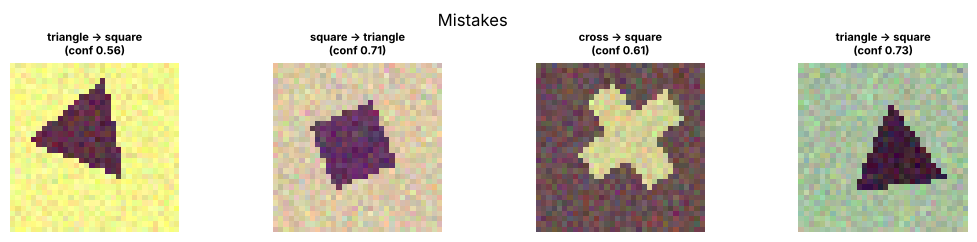

In [15]:
from sklearn.metrics import classification_report
with torch.no_grad(): p = net(Xte); pred = p.argmax(1).numpy(); conf = torch.softmax(p, 1).max(1).values.numpy()
print(classification_report(yte.numpy(), pred, target_names=names, digits=3))
wrong = np.where(pred != yte.numpy())[0]
if len(wrong):
    fig, axes = plt.subplots(1, min(8, len(wrong)), figsize=(13, 2.2))
    for ax, i in zip(np.atleast_1d(axes), wrong[:8]):
        ax.imshow(Xs[te_i[i]]); ax.set_title(f"{names[yte[i]]} -> {names[pred[i]]}\n(conf {conf[i]:.2f})", fontsize=8); ax.axis("off")
    plt.suptitle("Mistakes", y=1.12); plt.show()

## 🎓 Mini-quiz
1. Input 64×64, `Conv2d(k=5, padding=0, stride=1)` then `MaxPool2d(2)`: output size?
2. Why does global average pooling reduce overfitting compared with `Flatten + big Linear`?
3. Name one augmentation that would be **wrong** for classifying the digits 6 vs 9, and one that would be wrong for left vs right hand-written arrows.

<details><summary>Answers</summary>

1. (64−5)/1+1 = 60 → pool → 30×30. 2. It replaces a huge, image-size-dependent weight matrix by one number per channel → far fewer parameters. 3. 180° rotation for 6 vs 9; horizontal flip for left vs right arrows: they change the label.
</details>

        ---
        ## 🧾 Recap
        - A **convolution** slides a shared kernel over the image; stack **Conv → BatchNorm → ReLU → Pool** blocks.
- Output size $\lfloor (W-K+2P)/S\rfloor+1$; conv parameters $C_{out}(C_{in}K^2+1)$: independent of image size.
- **Global average pooling** gives compact heads; inspect **filters and feature maps** to understand what was learned.
- **Augmentation** (label-preserving, training-only) is the best cure for small-data overfitting.

**Next up:** Lesson 8.7; Project 3: classify diseased vs healthy crop leaves, evaluate like a field agronomist, and learn the transfer-learning recipe for real photos.